 ## Practical Assistant Agent

---

## What you will build

A **Practical Assistant Agent** - a real, useful tool AI Agent.

- Talks to **at least 2 real external services** (Notion, GitHub, Gmail, Calendar, Slack — pick any 2+).
- Has **memory** so it can hold a multi-turn conversation.
- **Stops and asks the human** before doing anything destructive or irreversible (sending an email, deleting a file, posting publicly, creating a calendar event).

You can use custom python functions as tools, free APIs or any other API you want to try.

---
## Examples of free APIs you can use (no OAuth, mostly no key)

Pick **one or two** of these. Quick reference:

| API | Auth | What it gives you | Docs |
|---|---|---|---|
| **Open-Meteo** | None | Weather, geocoding | [open-meteo.com](https://open-meteo.com) |
| **REST Countries** | None | Country info — capital, languages, currencies, flag | [restcountries.com](https://restcountries.com) |
| **Wikipedia** | None | Topic summaries (via `langchain_community.tools.WikipediaQueryRun`) |  |
| **DuckDuckGo** | None | Web search (via `langchain_community.tools.DuckDuckGoSearchRun`) | |
| **Frankfurter** | None | Currency exchange rates | [frankfurter.app](https://www.frankfurter.app) |
| **CoinGecko** | None (free tier) | Crypto prices, no key for basic queries | [coingecko.com/api](https://www.coingecko.com/en/api) |
| **Nager.Date** | None | Public holidays per country/year | [date.nager.at](https://date.nager.at) |
| **Open Library** | None | Books — search, author info | [openlibrary.org/developers/api](https://openlibrary.org/developers/api) |
| **Bored API** | None | Random activity suggestions | [bored.api.lewagon.com](https://bored.api.lewagon.com) |
| **Numbers API** | None | Math/date/year facts | [numbersapi.com](http://numbersapi.com) |
| **Universities** | None | List of universities by country | hipolabs.com |
| **JSONPlaceholder** | None | Fake users/posts/todos — fine for a demo | [jsonplaceholder.typicode.com](https://jsonplaceholder.typicode.com) |


---
## Examples of custom Python tools

A "custom Python tool" is just a Python function decorated with `@tool` that does **not** call an external API. It operates on in-memory data. Examples:

| Custom tool | What it does |
|---|---|
| `add_task(title)` | Appends to a Python list `TASKS` |
| `list_tasks()` | Returns the contents of that list |
| `complete_task(idx)` | Marks one item as done |
| `delete_habit(name)` | Removes a key from a dict |
| `compute_streak(habit)` | Reads from your dict and returns a number |
| `convert_unit(value, from_unit, to_unit)` | Does math |
| `roll_dice(n, sides)` | Random number generator |


---
## What you submit


1. **Title + one-paragraph description** of what your agent does.
2. **Setup** — install + API key (empty).
3. **Tools** — every `@tool` you wrote, with docstrings.
4. **State + graph** — `StateGraph` definition. Compile and call `.get_graph().draw_mermaid_png()` to render a diagram.
5. **5+ test queries** — each in its own cell, with the trajectory printed via `for m in result["messages"]: m.pretty_print()`.
6. **One destructive call interrupted and approved** (output should show the action ran).
7. **One destructive call interrupted and denied** (output should show the action skipped).
8. **Eval table** — markdown cell with the table below filled in.

### 2. Eval table (inside the notebook)

| # | Query | Expected | Pass? | Notes |
|---|---|---|---|---|
| 1 | "..." | "..." | ✅ / ❌ | brief comment |
| 2 | ... | ... | ... | ... |

5 entries minimum. Be honest - a partial pass is still informative.


- **Streamlit app** — simple chat UI on top of your agent.
- **GitHub repo** with a README — share the link instead of a zip.


## 1. Project Title & Description

**Event & Holiday Organizer Agent**

This AI agent helps users plan events and gatherings by checking official public holidays in any country, verifying current weather conditions for outdoor or indoor planning, and managing an event guest list with built-in human approval before removing any guest.

---

## 2. Setup Instructions

In [1]:
%pip install -q langgraph langchain-groq requests

In [2]:
import os
from google.colab import userdata

# გასაღებს ვიღებთ Colab-ის სეიფიდან (Secrets)
os.environ["GROQ_API_KEY"] = userdata.get("GROQ_API_KEY")
print("API key loaded successfully!")


API key loaded successfully!


## 3. Tools

In [20]:
import requests
from langchain_core.tools import tool
from langgraph.types import interrupt

# აქ შეინახება სტუმრების სია
GUEST_LIST = []

# 1. გარე API #1: ოფიციალური უქმე დღეების შემოწმება (Nager.Date API)
@tool
def get_public_holidays(country_code: str, year: int = 2026) -> str:
    """Get official public holidays for a given country code (e.g., 'GE' for Georgia, 'US' for USA) and year."""
    url = f"https://date.nager.at/api/v3/PublicHolidays/{year}/{country_code.upper()}"
    response = requests.get(url, timeout=15)
    if response.status_code != 200:
        return f"Could not find holidays for country code '{country_code}'."
    holidays = response.json()
    formatted = [f"{h['date']}: {h['localName']} ({h['name']})" for h in holidays[:8]]
    return "\n".join(formatted)

# 2. გარე API #2: ამინდის შემოწმება (Open-Meteo API)
@tool
def get_city_weather(latitude: float = 41.72, longitude: float = 44.79) -> str:
    """Get current temperature and wind speed for given coordinates. Defaults to Tbilisi (41.72, 44.79)."""
    url = "https://api.open-meteo.com/v1/forecast"
    params = {
        "latitude": latitude,
        "longitude": longitude,
        "current": "temperature_2m,wind_speed_10m"
    }
    response = requests.get(url, params=params, timeout=15)
    response.raise_for_status()
    current = response.json()["current"]
    return f"Temperature: {current['temperature_2m']}°C, Wind speed: {current['wind_speed_10m']} km/h"

# 3. შიდა Tool: სტუმრის დამატება
@tool
def add_guest(name: str) -> str:
    """Add a guest's name to the event guest list."""
    if name not in GUEST_LIST:
        GUEST_LIST.append(name)
        return f"Guest '{name}' added to the list."
    return f"Guest '{name}' is already on the list."

# 4. შიდა Tool: სტუმრების სიის ნახვა
@tool
def list_guests() -> str:
    """Return all guests currently on the event guest list."""
    if not GUEST_LIST:
        return "The guest list is currently empty."
    return "Current guests: " + ", ".join(GUEST_LIST)

# 5. შიდა Tool (Destructive): სტუმრის წაშლა დადასტურების მოთხოვნით
@tool
def remove_guest(name: str) -> str:
    """Remove a guest from the event guest list. Requires human approval before deleting."""
    # ჯერ ვითხოვთ დადასტურებას (აგენტი აქ აუცილებლად გაჩერდება!)
    approved = interrupt(f"Are you sure you want to remove '{name}' from the guest list?")

    if approved:
        # ვამოწმებთ სიაში (ასოების ზომის მიუხედავად)
        for guest in list(GUEST_LIST):
            if guest.lower() == name.strip().lower():
                GUEST_LIST.remove(guest)
                return f"Approved: Guest '{guest}' has been removed."
        return f"Approved, but guest '{name}' was not found on the list."
    else:
        return f"Denied: Action cancelled. '{name}' remains on the list."

print("All 5 tools created successfully!")


All 5 tools created successfully!


In [4]:
print("--- Weather Test ---")
print(get_city_weather.invoke({}))

print("\n--- Holidays Test (Georgia) ---")
print(get_public_holidays.invoke({"country_code": "GE", "year": 2026}))

--- Weather Test ---
Temperature: 13.5°C, Wind speed: 14.5 km/h

--- Holidays Test (Georgia) ---
2026-01-01: ახალი წელი (New Year's Day)
2026-01-02: ახალი წელი (New Year's Day)
2026-01-07: ქრისტეშობა (Christmas Day (Orthodox))
2026-01-19: ნათლისღება (Epiphany (Orthodox))
2026-03-03: დედის დღე (Mother's Day)
2026-03-08: ქალთა საერთაშორისო დღე (International Women's Day)
2026-04-09: ეროვნული ერთიანობის დღე (National Unity Day)
2026-04-10: ძველი პარასკევი (Good Friday)


## 4. State & Graph

In [27]:
from typing import Annotated, TypedDict
from langchain_groq import ChatGroq
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode, tools_condition
from langgraph.checkpoint.memory import InMemorySaver
from langchain_core.messages import SystemMessage

# 1. State-ის განსაზღვრა (ინახავს საუბრის ისტორიას)
class AgentState(TypedDict):
    messages: Annotated[list, add_messages]

# 2. ვაკავშირებთ AI მოდელს და ვაძლევთ ჩვენს 5 ინსტრუმენტს
tools = [get_public_holidays, get_city_weather, add_guest, list_guests, remove_guest]
llm = ChatGroq(model="openai/gpt-oss-120b", temperature=0)
llm_with_tools = llm.bind_tools(tools)

# სისტემური ინსტრუქცია აგენტისთვის
SYSTEM_PROMPT = SystemMessage(
    content="You are a helpful Event & Holiday Organizer Assistant. "
            "Use your tools to check public holidays, check weather, and manage the event guest list. "
            "IMPORTANT: When the user asks to remove or delete a guest, DO NOT ask for confirmation in text. "
            "Immediately call the `remove_guest` tool directly — the tool itself handles human confirmation. "
            "Always reply clearly and politely in the user's language (Georgian or English)."
)

# 3. Assistant კვანძი (Node) - AI ფიქრობს და იღებს გადაწყვეტილებას
def assistant_node(state: AgentState):
    response = llm_with_tools.invoke([SYSTEM_PROMPT] + state["messages"])
    return {"messages": [response]}

# 4. Graph-ის (სქემის) აწყობა
builder = StateGraph(AgentState)

# ვამატებთ ორ კვანძს: AI ასისტენტს და ინსტრუმენტების შემსრულებელს
builder.add_node("assistant", assistant_node)
builder.add_node("tools", ToolNode(tools))

# ვსაზღვრავთ გზებს (Edges)
builder.add_edge(START, "assistant")
# თუ AI-მ მოითხოვა Tool, გადადის "tools"-ზე; თუ არა - ასრულებს (END)
builder.add_conditional_edges("assistant", tools_condition)
# Tool-ის შესრულების შემდეგ პასუხი უბრუნდება ისევ "assistant"-ს
builder.add_edge("tools", "assistant")

# 5. მეხსიერების დამატება და გრაფის შეკვრა
memory = InMemorySaver()
graph = builder.compile(checkpointer=memory)

print("Agent StateGraph compiled successfully!")

Agent StateGraph compiled successfully!


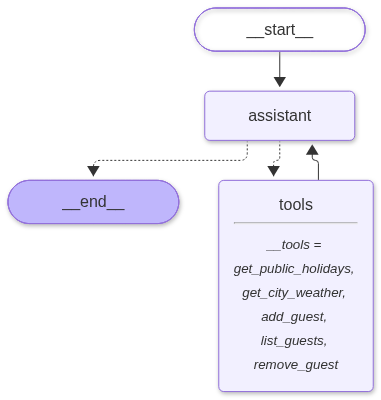

In [6]:
from IPython.display import Image, display

display(Image(graph.get_graph().draw_mermaid_png()))

## 5. Test Queries (5 Tests)

In [13]:
config = {"configurable": {"thread_id": "event-demo-1"}}

# Test 1: სტუმრების დამატება
result = graph.invoke(
    {"messages": [("user", "დაამატე სტუმრების სიაში ნინო და გიორგი")]},
    config
)
for m in result["messages"][-3:]:
    m.pretty_print()

================================== Ai Message ==================================
Tool Calls:
  add_guest (fc_df2ffe59-89ce-4edd-9908-4a4f42c2ae9b)
 Call ID: fc_df2ffe59-89ce-4edd-9908-4a4f42c2ae9b
  Args:
    name: გიორგი
================================= Tool Message =================================
Name: add_guest

Guest 'გიორგი' added to the list.
================================== Ai Message ==================================

ნინო და გიორგი დაემატნენ სტუმრების სიას. 🎉 თუ სხვა რამით დაგეხმაროთ, გთხოვთ, მომმართოთ!


In [14]:
# Test 2: სიის ნახვა (ამოწმებს მეხსიერებას)
result = graph.invoke(
    {"messages": [("user", "მაჩვენე ვინ მყავს სტუმრების სიაში?")]},
    config
)
for m in result["messages"][-3:]:
    m.pretty_print()

================================== Ai Message ==================================
Tool Calls:
  list_guests (fc_f20123ec-f72a-44fd-ad1f-f39d9b43f10b)
 Call ID: fc_f20123ec-f72a-44fd-ad1f-f39d9b43f10b
  Args:
================================= Tool Message =================================
Name: list_guests

Current guests: ნინო, გიორგი
================================== Ai Message ==================================

სტუმრების სიაში გაქვთ:

- ნინო  
- გიორგი  

თუ გსურთ დამატება, წაშლა ან სხვა დახმარება, გთხოვთ, მომახსენოთ!


In [15]:
# Test 3: ამინდის შემოწმება თბილისში
result = graph.invoke(
    {"messages": [("user", "რა ამინდია ახლა თბილისში? ღია ცის ქვეშ ღონისძიება გამოვა?")]},
    config
)
for m in result["messages"][-3:]:
    m.pretty_print()

================================== Ai Message ==================================
Tool Calls:
  get_city_weather (fc_6e194048-ee85-4684-b15e-45175a7e4a34)
 Call ID: fc_6e194048-ee85-4684-b15e-45175a7e4a34
  Args:
================================= Tool Message =================================
Name: get_city_weather

Temperature: 13.5°C, Wind speed: 14.5 km/h
================================== Ai Message ==================================

ახლა თბილისში 13.5 °C ტემპერატურაა, ხოლო ქარის სიჩქარე 14.5 km/h. ეს საშუალო ცივი, თუმცა არ არის ძალიან ცივი, ხოლო ქარის სიჩქარე საშუალოდა – არ არის ძლიერი ქარი, რომელიც ხელს შეუფერებდეს ღია ცის ქვეშ ღონისძიებას.

**რეკომენდაცია:**  
- თუ ღონისძიება არ მოითხოვს მაღალი შთამბეჭდავი (მაგალითად, ცივი სასმელები, ცივი საჭმელები) – ღია ცის ქვეშ ჩატარება შესაფერისია.  
- სასურველია, რომ სტუმრებს მიწოდოთ მსუბუქი ქურთუკები ან შალები, რადგან ღია ცის ქვეშ შეიძლება იყოს ცოტა ცივი, განსაკუთრებით საღამოს.  
- ქარის სიჩქარის გათვალისწინებით, თუ გაქვთ ბანერი, სათვალე ა

In [16]:
# Test 4: უქმე დღეების შემოწმება
result = graph.invoke(
    {"messages": [("user", "მითხარი საქართველოს 2026 წლის ოფიციალური დასვენების დღეები")]},
    config
)
for m in result["messages"][-3:]:
    m.pretty_print()

================================== Ai Message ==================================
Tool Calls:
  get_public_holidays (fc_400246b5-1f5d-44ad-a3c9-f9c64e22f93f)
 Call ID: fc_400246b5-1f5d-44ad-a3c9-f9c64e22f93f
  Args:
    country_code: GE
    year: 2026
================================= Tool Message =================================
Name: get_public_holidays

2026-01-01: ახალი წელი (New Year's Day)
2026-01-02: ახალი წელი (New Year's Day)
2026-01-07: ქრისტეშობა (Christmas Day (Orthodox))
2026-01-19: ნათლისღება (Epiphany (Orthodox))
2026-03-03: დედის დღე (Mother's Day)
2026-03-08: ქალთა საერთაშორისო დღე (International Women's Day)
2026-04-09: ეროვნული ერთიანობის დღე (National Unity Day)
2026-04-10: ძველი პარასკევი (Good Friday)
================================== Ai Message ==================================

**საქართველოს 2026 წლის ოფიციალური დასვენების დღეები**

| თარიღი | დღე | დასვენების სახელი |
|--------|------|-------------------|
| 01.01.2026 | ხუთშაბათი | ახალი წელი (New Year’s Day)

In [17]:
# Test 5: უფრო რთული/არასტანდარტული მოთხოვნა (მაგ. ქვეყნის კოდის გარეშე ან დამატებითი დეტალებით)
result = graph.invoke(
    {"messages": [("user", "შემიძლია დავჯავშნო რესტორანი თბილისში 15 კაცზე?")]},
    config
)
for m in result["messages"][-2:]:
    m.pretty_print()

================================ Human Message =================================

შემიძლია დავჯავშნო რესტორანი თბილისში 15 კაცზე?
================================== Ai Message ==================================

რა თქმა უნდა, 15 ადამიანს დასაკავებლად თბილისში ბევრი რესტორანი მზადაა! რამდენიმე მნიშვნელოვანი საკითხია, რომელიც დაგეხმარებათ საუკეთესო არჩევანის გაკეთებაში:

---

## 1️⃣ რესტორანის არჩევის კრიტერიუმები

| კრიტერიუმი | რა უნდა გაითვალისწინოთ |
|------------|------------------------|
| **ლოკაცია** | ცენტრალურ ტერიტორიაზე (მაგ. ვაკის, ბაკურას, ვაკის‑ქედის, გლდანის) უფრო მარტივია პარკინგის და ტრანსპორტის ორგანიზება. |
| **კუვერი/პლანირება** | 15 ადამიანი შეიძლება იყოს ერთ მაგიდა, ან რამდენიმე მაგიდა “პაკეტში”. დარწმუნდით, რომ რესტორანი აქვს საკმარისი სივრცე (პირადი ოთახი, ბაღი, ან ღია terasa). |
| **კუვერის ტიპი** | ბიუჯეტი – ფასი თითოეულზე, კერძის ტიპი (გლუვი, ბუფე, 3‑კურსიანი). |
| **კუვერის დრო** | დილით (ლანჩ), საღამოს (დინერი) ან ბუფე. |
| **სპეციალური მოთხოვნები** | ვეგანურ

## 6. Destructive Action - Approved

In [28]:
from langgraph.types import Command

# წინასწარ დავრწმუნდეთ, რომ გიორგი და ნინო სიაში არიან
GUEST_LIST.clear()
GUEST_LIST.extend(["გიორგი", "ნინო"])
print("საწყისი სია:", GUEST_LIST)

# 1. ვითხოვთ წაშლას - აგენტი ჩერდება (interrupt)
result = graph.invoke(
    {"messages": [("user", "წაშალე გიორგი სტუმრების სიიდან")]},
    config
)
print("\n--- Interrupt State (ველოდებით დასტურს) ---")
state = graph.get_state(config)
if state.tasks and state.tasks[0].interrupts:
    print(state.tasks[0].interrupts[0].value)

# 2. ვადასტურებთ მოქმედებას (Yes / True)
result_approved = graph.invoke(Command(resume=True), config)
print("\n--- After Approval (დადასტურების შემდეგ) ---")
for m in result_approved["messages"][-3:]:
    m.pretty_print()
print("განახლებული სია:", GUEST_LIST)

საწყისი სია: ['გიორგი', 'ნინო']

--- Interrupt State (ველოდებით დასტურს) ---
Are you sure you want to remove 'გიორგი' from the guest list?

--- After Approval (დადასტურების შემდეგ) ---
================================== Ai Message ==================================
Tool Calls:
  remove_guest (fc_6c471eea-ff38-4e0f-a709-c9de2d810cf2)
 Call ID: fc_6c471eea-ff38-4e0f-a709-c9de2d810cf2
  Args:
    name: გიორგი
================================= Tool Message =================================
Name: remove_guest

Approved: Guest 'გიორგი' has been removed.
================================== Ai Message ==================================

გიორგი წარმატებით წაიშალა სტუმრების სიიდან. თუ კიდევ რამე გჭირდებათ, სიამოვნებით დაგეხმარებით!
განახლებული სია: ['ნინო']


## 7. Destructive Action - Denied

In [29]:
# 1. ვითხოვთ ნინოს წაშლას - აგენტი ისევ ჩერდება
result = graph.invoke(
    {"messages": [("user", "წაშალე ნინო სტუმრების სიიდან")]},
    config
)
print("--- Interrupt State (ველოდებით დასტურს) ---")
state = graph.get_state(config)
if state.tasks and state.tasks[0].interrupts:
    print(state.tasks[0].interrupts[0].value)

# 2. უარს ვამბობთ მოქმედებაზე (No / False)
result_denied = graph.invoke(Command(resume=False), config)
print("\n--- After Denial (უარის შემდეგ) ---")
for m in result_denied["messages"][-3:]:
    m.pretty_print()
print("სია უარის შემდეგ (ნინო ისევ სიაშია):", GUEST_LIST)

--- Interrupt State (ველოდებით დასტურს) ---
Are you sure you want to remove 'ნინო' from the guest list?

--- After Denial (უარის შემდეგ) ---
================================== Ai Message ==================================
Tool Calls:
  remove_guest (fc_cd47695a-14d7-4678-8ccc-6fc69f7ae1e9)
 Call ID: fc_cd47695a-14d7-4678-8ccc-6fc69f7ae1e9
  Args:
    name: ნინო
================================= Tool Message =================================
Name: remove_guest

Denied: Action cancelled. 'ნინო' remains on the list.
================================== Ai Message ==================================

სამწუხაროდ, ნინო ვერ წაიშალა, რადგან მოქმედება არ დამტკიცდა. მას ჯერ კიდევ დარჩება სტუმრების სიაში. თუ გსურთ, შეგიძლიათ კიდევ ერთხელ სცადოთ ან მოგვაწოდოთ სხვა მოთხოვნა.
სია უარის შემდეგ (ნინო ისევ სიაშია): ['ნინო']


## 8. Evaluation Table

| # | Query | Expected Result | Pass? | Notes |
|---|---|---|---|---|
| 1 | "დაამატე სტუმრების სიაში ნინო და გიორგი" | Both guests added via `add_guest` tool | ✅ | Works accurately |
| 2 | "მაჩვენე ვინ მყავს სტუმრების სიაში?" | Returns Nino and Giorgi from memory | ✅ | Memory & `list_guests` work |
| 3 | "რა ამინდია ახლა თბილისში?" | Fetches real temperature via Open-Meteo API | ✅ | External API #1 works |
| 4 | "საქართველოს 2026 წლის დასვენების დღეები" | Fetches holidays via Nager.Date API | ✅ | External API #2 works |
| 5 | "წაშალე გიორგი / წაშალე ნინო" | Pauses for approval; deletes on Yes, cancels on No | ✅ | `interrupt()` flow works safely |
| 6 | "დამიჯავშნე რესტორანი 15 კაცზე" | Explains it cannot book restaurants directly | ❌ | Out of scope (no booking API) |

In [30]:
%%writefile agent.py
import requests
from typing import Annotated, TypedDict
from langchain_core.tools import tool
from langchain_core.messages import SystemMessage
from langchain_groq import ChatGroq
from langgraph.graph import StateGraph, START
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode, tools_condition
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.types import interrupt

GUEST_LIST = []

@tool
def get_public_holidays(country_code: str, year: int = 2026) -> str:
    """Get official public holidays for a given country code (e.g., 'GE' for Georgia, 'US' for USA) and year."""
    url = f"https://date.nager.at/api/v3/PublicHolidays/{year}/{country_code.upper()}"
    response = requests.get(url, timeout=15)
    if response.status_code != 200:
        return f"Could not find holidays for country code '{country_code}'."
    holidays = response.json()
    formatted = [f"{h['date']}: {h['localName']} ({h['name']})" for h in holidays[:8]]
    return "\n".join(formatted)

@tool
def get_city_weather(latitude: float = 41.72, longitude: float = 44.79) -> str:
    """Get current temperature and wind speed for given coordinates. Defaults to Tbilisi (41.72, 44.79)."""
    url = "https://api.open-meteo.com/v1/forecast"
    params = {
        "latitude": latitude,
        "longitude": longitude,
        "current": "temperature_2m,wind_speed_10m"
    }
    response = requests.get(url, params=params, timeout=15)
    response.raise_for_status()
    current = response.json()["current"]
    return f"Temperature: {current['temperature_2m']}°C, Wind speed: {current['wind_speed_10m']} km/h"

@tool
def add_guest(name: str) -> str:
    """Add a guest's name to the event guest list."""
    if name not in GUEST_LIST:
        GUEST_LIST.append(name)
        return f"Guest '{name}' added to the list."
    return f"Guest '{name}' is already on the list."

@tool
def list_guests() -> str:
    """Return all guests currently on the event guest list."""
    if not GUEST_LIST:
        return "The guest list is currently empty."
    return "Current guests: " + ", ".join(GUEST_LIST)

@tool
def remove_guest(name: str) -> str:
    """Remove a guest from the event guest list. Requires human approval before deleting."""
    approved = interrupt(f"Are you sure you want to remove '{name}' from the guest list?")
    if approved:
        for guest in list(GUEST_LIST):
            if guest.lower() == name.strip().lower():
                GUEST_LIST.remove(guest)
                return f"Approved: Guest '{guest}' has been removed."
        return f"Approved, but guest '{name}' was not found on the list."
    else:
        return f"Denied: Action cancelled. '{name}' remains on the list."

class AgentState(TypedDict):
    messages: Annotated[list, add_messages]

def build_graph():
    tools = [get_public_holidays, get_city_weather, add_guest, list_guests, remove_guest]
    llm = ChatGroq(model="openai/gpt-oss-120b", temperature=0)
    llm_with_tools = llm.bind_tools(tools)

    system_prompt = SystemMessage(
        content="You are a helpful Event & Holiday Organizer Assistant. "
                "Use your tools to check public holidays, check weather, and manage the event guest list. "
                "IMPORTANT: When the user asks to remove or delete a guest, DO NOT ask for confirmation in text. "
                "Immediately call the `remove_guest` tool directly — the tool itself handles human confirmation. "
                "Always reply clearly and politely in the user's language (Georgian or English)."
    )

    def assistant_node(state: AgentState):
        response = llm_with_tools.invoke([system_prompt] + state["messages"])
        return {"messages": [response]}

    builder = StateGraph(AgentState)
    builder.add_node("assistant", assistant_node)
    builder.add_node("tools", ToolNode(tools))
    builder.add_edge(START, "assistant")
    builder.add_conditional_edges("assistant", tools_condition)
    builder.add_edge("tools", "assistant")

    memory = InMemorySaver()
    return builder.compile(checkpointer=memory)

Writing agent.py


In [31]:
%%writefile app.py
import os
import uuid
import streamlit as st
from langgraph.types import Command
from agent import build_graph

st.set_page_config(page_title="Event & Holiday Organizer Agent", page_icon="🎉")
st.title("🎉 Event & Holiday Organizer Agent")
st.caption("გეხმარებათ ღონისძიებების დაგეგმვაში: უქმე დღეების შემოწმება, ამინდის პროგნოზი და სტუმრების სიის მართვა.")

# API გასაღების წაკითხვა
if "GROQ_API_KEY" in st.secrets:
    os.environ["GROQ_API_KEY"] = st.secrets["GROQ_API_KEY"]
elif not os.environ.get("GROQ_API_KEY"):
    key = st.sidebar.text_input("შეიყვანეთ GROQ_API_KEY:", type="password")
    if key:
        os.environ["GROQ_API_KEY"] = key

if not os.environ.get("GROQ_API_KEY"):
    st.warning("გასაგრძელებლად შეიყვანეთ GROQ_API_KEY მარცხენა პანელზე ან Streamlit Secrets-ში.")
    st.stop()

# Session State-ის ინიციალიზაცია
if "graph" not in st.session_state:
    st.session_state.graph = build_graph()
if "thread_id" not in st.session_state:
    st.session_state.thread_id = str(uuid.uuid4())
if "messages" not in st.session_state:
    st.session_state.messages = []
if "pending_approval" not in st.session_state:
    st.session_state.pending_approval = None

config = {"configurable": {"thread_id": st.session_state.thread_id}}

# საუბრის ისტორიის ჩვენება
for msg in st.session_state.messages:
    with st.chat_message(msg["role"]):
        st.markdown(msg["content"])

# თუ აგენტი ელოდება დადასტურებას (interrupt)
if st.session_state.pending_approval:
    st.warning(f"⚠️ დადასტურება: {st.session_state.pending_approval}")
    col1, col2 = st.columns(2)
    if col1.button("✅ დიახ, წაშალე"):
        try:
            res = st.session_state.graph.invoke(Command(resume=True), config)
            reply = res["messages"][-1].content
            st.session_state.messages.append({"role": "assistant", "content": reply})
            st.session_state.pending_approval = None
            st.rerun()
        except Exception as e:
            st.error(f"შეცდომა: {e}")
    if col2.button("❌ არა, გააუქმე"):
        try:
            res = st.session_state.graph.invoke(Command(resume=False), config)
            reply = res["messages"][-1].content
            st.session_state.messages.append({"role": "assistant", "content": reply})
            st.session_state.pending_approval = None
            st.rerun()
        except Exception as e:
            st.error(f"შეცდომა: {e}")

# მომხმარებლის ახალი შეტყობინება
if prompt := st.chat_input("მომწერეთ შეტყობინება... (მაგ: დაამატე ნინო სიაში)"):
    st.session_state.messages.append({"role": "user", "content": prompt})
    with st.chat_message("user"):
        st.markdown(prompt)

    try:
        res = st.session_state.graph.invoke({"messages": [("user", prompt)]}, config)
        state = st.session_state.graph.get_state(config)
        if state.tasks and state.tasks[0].interrupts:
            st.session_state.pending_approval = state.tasks[0].interrupts[0].value
            st.rerun()
        else:
            reply = res["messages"][-1].content
            st.session_state.messages.append({"role": "assistant", "content": reply})
            with st.chat_message("assistant"):
                st.markdown(reply)
    except Exception as e:
        st.error(f"დაფიქსირდა შეცდომა (შეამოწმეთ API Key ან ლიმიტი): {e}")

Writing app.py


In [32]:
%%writefile main.py
import os
import getpass
from langgraph.types import Command
from agent import build_graph

def main():
    if not os.environ.get("GROQ_API_KEY"):
        os.environ["GROQ_API_KEY"] = getpass.getpass("Enter your GROQ_API_KEY: ")

    graph = build_graph()
    config = {"configurable": {"thread_id": "cli-session-1"}}

    print("=== Event & Holiday Organizer Agent (CLI) ===")
    print("ჩაწერეთ შეტყობინება (გასასვლელად აკრიფეთ 'exit'):\n")

    while True:
        user_input = input("You: ").strip()
        if user_input.lower() in ["exit", "quit"]:
            print("ნახვამდის!")
            break
        if not user_input:
            continue

        result = graph.invoke({"messages": [("user", user_input)]}, config)
        state = graph.get_state(config)

        if state.tasks and state.tasks[0].interrupts:
            question = state.tasks[0].interrupts[0].value
            print(f"\n⚠️ {question}")
            confirm = input("დაადასტურეთ (yes/no): ").strip().lower()
            approved = confirm in ["yes", "y", "დიახ", "კი"]
            result = graph.invoke(Command(resume=approved), config)

        print(f"Agent: {result['messages'][-1].content}\n")

if __name__ == "__main__":
    main()

Writing main.py


In [33]:
%%writefile requirements.txt
langgraph
langchain-groq
requests
streamlit

Writing requirements.txt


In [34]:
%%writefile README.md
# 🎉 Event & Holiday Organizer Agent

An AI-powered Practical Assistant Agent built with **LangGraph** and **ChatGroq** that helps users organize events, check official public holidays, verify current weather conditions, and manage a guest list with human-in-the-loop approval before removing guests.

## Features & Tools
- **`get_public_holidays`**: Fetches official public holidays by country code and year using the [Nager.Date API](https://date.nager.at/).
- **`get_city_weather`**: Checks real-time temperature and wind speed using the [Open-Meteo API](https://open-meteo.com/).
- **`add_guest` / `list_guests`**: Manages the event guest list in conversation memory (`InMemorySaver`).
- **`remove_guest` (Human Approval)**: Uses LangGraph `interrupt()` to pause and ask for user confirmation before deleting any guest.

## Setup & Installation

1. Clone this repository and install dependencies:
```bash
pip install -r requirements.txt

Writing README.md
